# Corridas bancarias como transiciones colectivas
## Laboratorio reproducible con un millón de agentes y comparación de topologías
**Reyes Miguel A. · JICES 2026 · Versión ampliada y auditada**

Este cuaderno integra los ocho scripts aportados (`networks.py`, `glauber.py`, `montecarlo.py`, `meanfield.py`, `analysis.py`, `figures.py`, `run_experiments.py` y `generate_all_figures.py`), el notebook Jupyter previo y las ecuaciones de la ponencia. Los archivos `code/ising_1m_core.py`, `code/run_study.py` y `code/extra_figures.py` contienen la implementación completa y quedan editables en el paquete.

**Alcance:** $N=1\,000\,000$ agentes sintéticos por red; los resultados no son observaciones bancarias. Se comparan redes con aproximadamente ocho enlaces por depositante. Se distinguen *shocks globales* y *shocks focalizados en los nodos más conectados* para no confundir el efecto de la topología con el de la localización del shock.

**Evidencia:** resultados Monte Carlo con semillas registradas y gráficos guardados en `figuras/`; archivos de resumen en `datos/`. Para reconstruir los resultados, activar `RECALCULAR = True` en la sección de ejecución (puede requerir varios minutos).

## 1. Formulación matemática y diccionario de parámetros

Cada depositante $i\in\{1,\ldots,N\}$ posee un estado binario:

$$s_i(t)\in\{-1,+1\},\qquad +1=\text{mantener},\quad -1=\text{retirar}. $$

La **confianza agregada** y la **fracción de retiros** son:

$$M(t)=\frac{1}{N}\sum_{i=1}^{N}s_i(t),\qquad R(t)=\frac{1-M(t)}2.$$

El grafo $G=(V,E)$ representa vínculos informativos. $A_{ij}=1$ si hay vínculo entre $i$ y $j$, y $0$ en otro caso. $k_i=\sum_j A_{ij}$ es el grado del agente. Se usa el promedio local normalizado:

$$W_{ij}=\begin{cases}A_{ij}/k_i&k_i>0\\0&k_i=0,\end{cases}\qquad z_i(t)=\sum_jW_{ij}s_j(t).$$

**Advertencia matemática:** $W=D^{-1}A$ no suele ser simétrica aunque $A$ sí lo sea. La regla bancaria sincrónica descrita más adelante **no debe presentarse como una cadena de Glauber reversible con distribución estacionaria de Gibbs**.

## 2. Campo efectivo, decisión de Glauber y liquidez endógena

En el modelo operacional:

$$H_i(t)=J z_i(t)+h_0+\lambda[L(t)-\bar L]-q\,a_i(t)+\omega I+\theta_i.$$

- $J\ge0$: intensidad de imitación de las decisiones observadas; un $J$ alto refuerza el consenso vigente.
- $h_0$: confianza basal; $\lambda$: sensibilidad a la liquidez; $L(t)$: liquidez bancaria normalizada; $\bar L$: liquidez objetivo.
- $q\ge0$: intensidad del shock; $a_i(t)$ indica si el depositante $i$ fue alcanzado por el shock durante su ventana temporal.
- $I$: medida externa que mejora la confianza; $\omega$: eficacia sobre el campo. Es un **campo exógeno de escenario**, no un problema de teoría de control.
- $\theta_i\sim\mathcal N(0,\sigma_\theta^2)$: heterogeneidad fija de cada depositante.
- $\beta>0$: sensibilidad probabilística. No es temperatura física; valores grandes generan decisiones menos ruidosas.

La probabilidad de mantener se actualiza de forma sincrónica:

$$P[s_i(t+1)=+1\mid\mathcal F_t]=\frac{1}{1+\exp[-2\beta H_i(t)]}. $$

Cada estado se sortea condicionalmente al estado anterior. El paso bancario **no es** un barrido clásico de Glauber reversible.

La liquidez se actualiza tras contabilizar los retiros:

$$L(t+1)=\Pi_{[0,1]}\big(L(t)+\rho[\bar L-L(t)]-c R(t+1)+\eta u(t)+\sigma_L\varepsilon_{t+1}\big).$$

En los experimentos presentes $u(t)=0$ y $\sigma_L=0$; $\rho$ es la recuperación relativa por paso y $c$ mide drenaje de liquidez por unidad de retiro agregado. $\Pi$ trunca a $[0,1]$.

**Criterio operativo de corrida:** existe $t$ tal que $R(t),R(t+1),R(t+2)\ge r_c=0.55$. No basta con que la curva supere brevemente el 55 %.

## 3. Parámetros: tabla base y escenario para mostrar el papel de la topología

Se mantienen los parámetros del artículo cuando corresponde: $\beta=1.20$, $h_0=0.80$, $\bar L=0.62$, $\lambda=1.10$, $\rho=0.05$, $c=0.08$, $\sigma_\theta=0.20$, $\omega=0.90$, $r_c=0.55$, persistencia de 3 pasos.

La comparación **focalizada** utiliza un escenario exploratorio cercano a una región de amplificación: $J=1.00$, $h_0=0.60$, $L_0=0.57$, $q=2.70$, shock de nueve pasos sobre el **18 % de nodos de mayor grado**. Este escenario fue identificado mediante pruebas piloto para estudiar cómo importa la topología; **no** implica calibración a datos reales. El experimento con shock distribuido aleatoriamente utiliza exactamente los mismos valores y la misma fracción afectada. Para la prueba de shock global se usa un conjunto diferente, declarado en cada figura ($J=0.83$, $L_0=0.55$, $q=0.80$, $h_0=0.80$).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'code'/'ising_1m_core.py').exists() and (ROOT.parent/'code'/'ising_1m_core.py').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'code'))
from ising_1m_core import Params, network_matrix, simulate, seed_mask, degree_metrics, estimate_run_probability
D=ROOT/'datos'; F=ROOT/'figuras'
BASE=Params(n=1_000_000,k=8)
print('Directorio',ROOT,'N',BASE.n)
print('Resultados disponibles',len(list(D.glob('*.csv'))))

Directorio c:\2023\Investigación\modelo ising financiero\final\Corridas_Bancarias_Ising_N1000000_Proyecto_Completo\Ising_1M_Comparacion N 1000000
Resultados disponibles 36


## 4. Generación eficiente de redes con $N=10^6$

Una matriz densa de $10^6\times10^6$ requiere $10^{12}$ elementos y no es apropiada. El código construye matrices dispersas CSR con alrededor de $8\times10^6$ entradas no nulas por red (grado medio $\langle k\rangle\approx8$).

**Erdős–Rényi (ER):** se muestrean aproximadamente $Nk/2$ enlaces aleatorios, con eliminación de lazos y duplicados. Es un análogo $G(N,M)$ de $G(N,p)$ con $p\approx k/(N-1)$.

**Watts–Strogatz (WS):** inicia con un anillo regular con $k=8$ vecinos; después reconecta una proporción $q_r=0.08$ de enlaces. Conserva agrupamiento elevado.

**Barabási–Albert (BA):** crecimiento por apego preferencial con $m=k/2=4$ enlaces por nuevo nodo. Produce grados muy heterogéneos y nodos centrales o *hubs*. La implementación usa `numba` y un vector de extremos de arista para no construir objetos Python para cada agente.

Para comparar topologías se igualan $N$ y $\langle k\rangle$, pero no necesariamente el número exacto de aristas ni el espectro; la estructura residual es el objeto del análisis.

,mean_degree,std_degree,cv_degree,max_degree,isolates,degree_p99,red,N,links
0,8.0,2.8287,0.3536,24,339,15.0,ER,1000000,3999977
1,8.0,0.7841,0.0980,14,0,10.0,WS,1000000,3999998
2,8.0,14.6170,1.8271,3037,0,44.0,BA,1000000,3999990


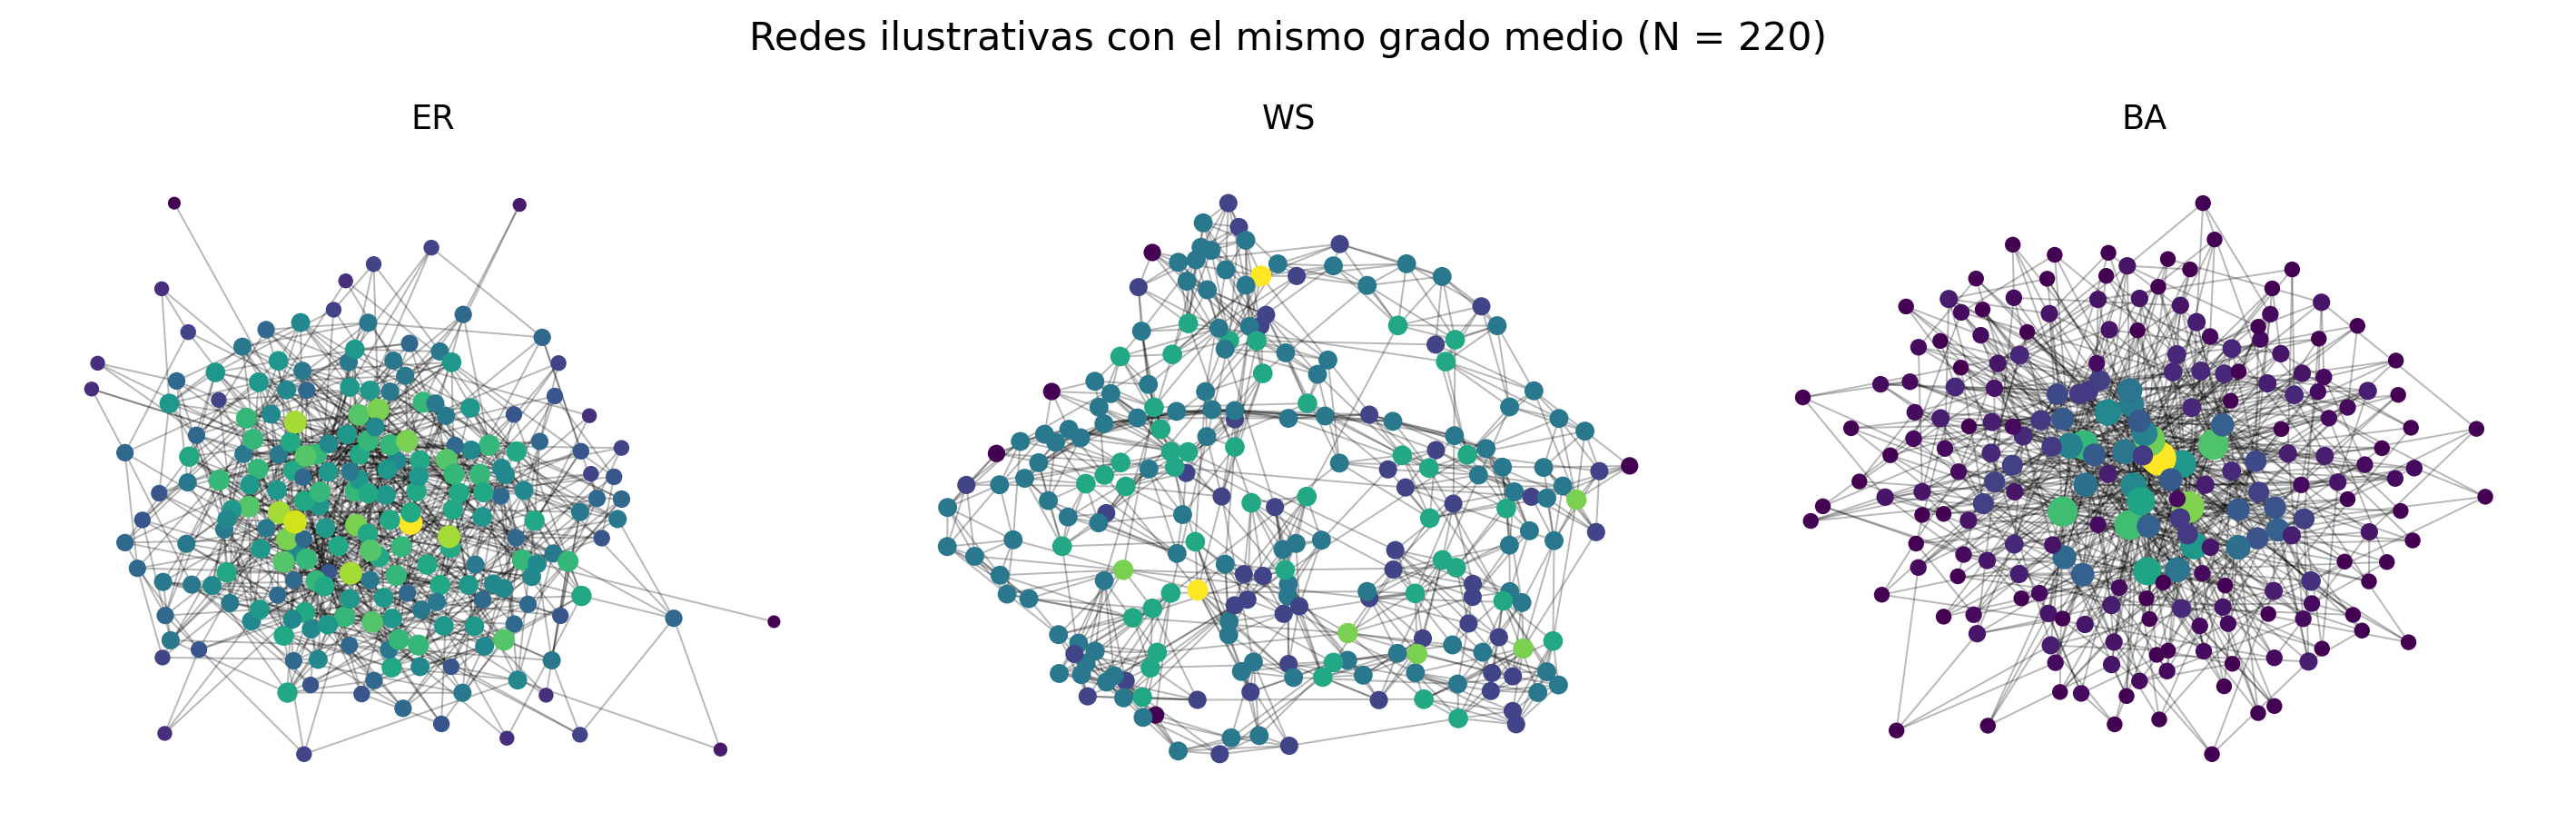

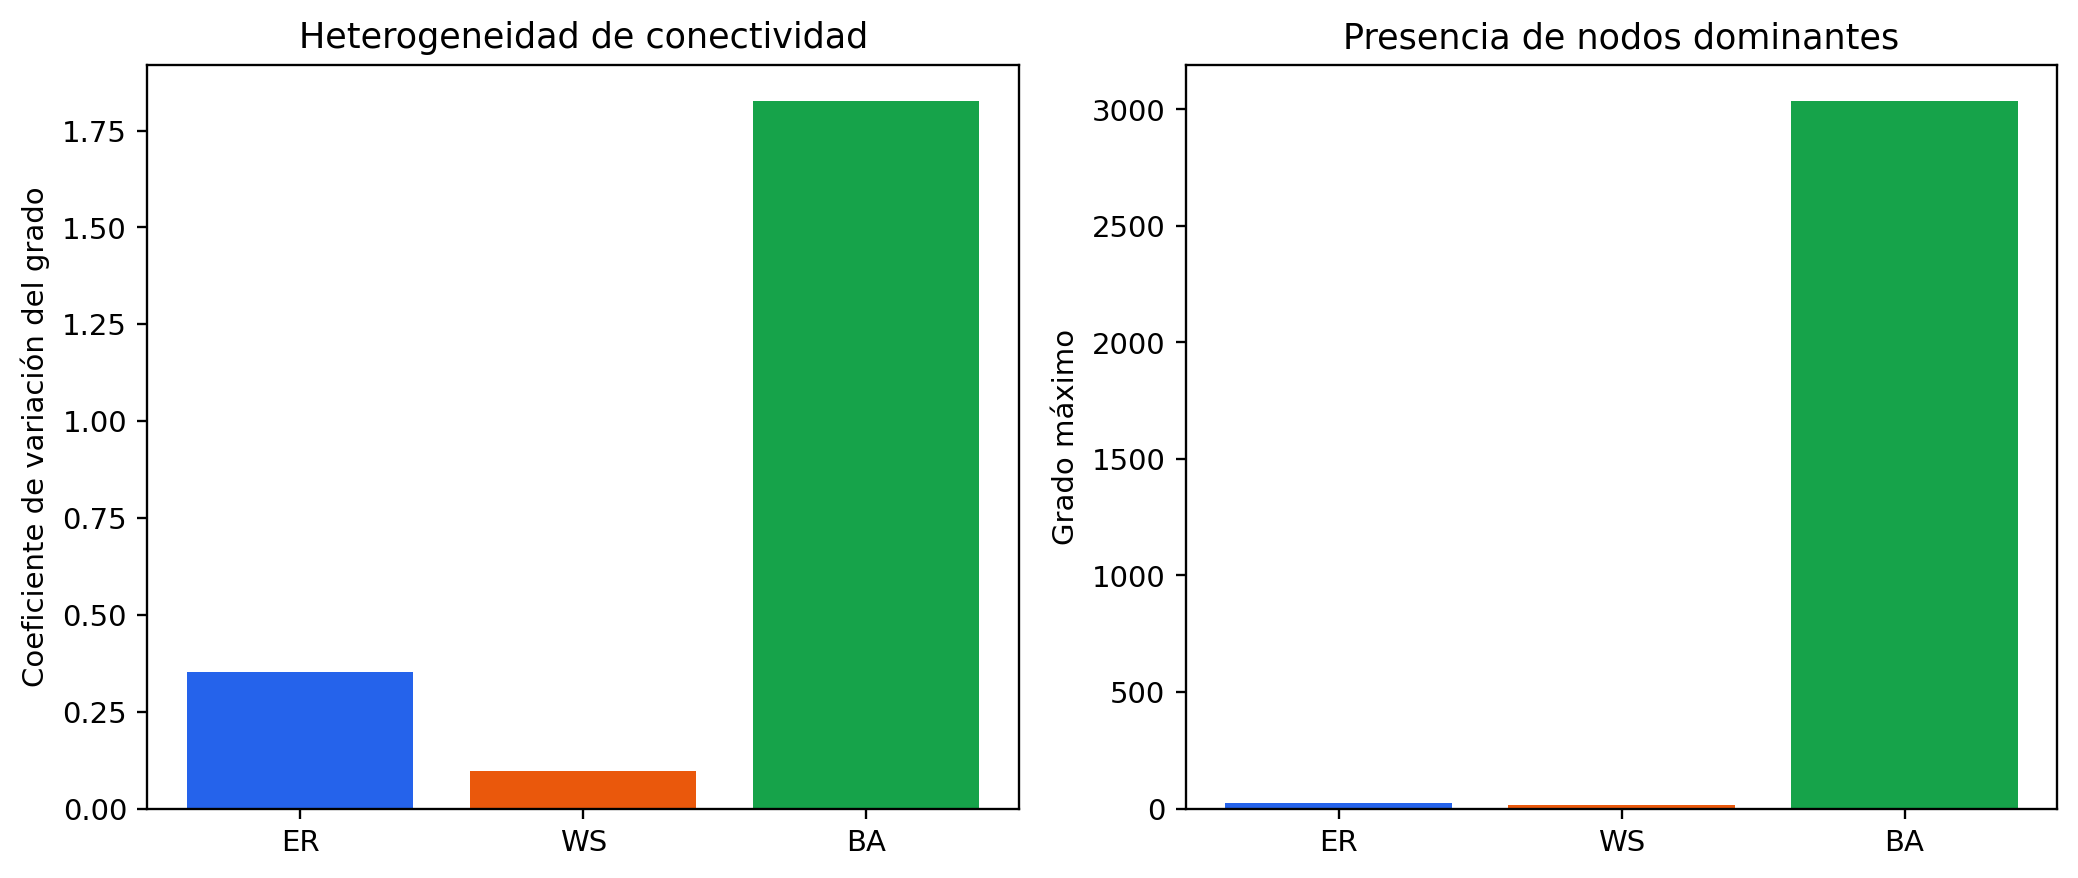

In [2]:
display(pd.read_csv(D/'metricas_redes_N1M.csv').round(4))
display(Image(filename=str(F/'11_topologias_ilustrativas.png')))
display(Image(filename=str(F/'01_heterogeneidad_redes_N1M.png')))

## 5. Diferencia fundamental entre modelo bancario y Glauber asincrónico

Para un **Ising reversible** sobre matriz de adyacencia simétrica $A$ y acoplamiento $J_c$, el Hamiltoniano es:

$$\mathcal H(\mathbf s)=-\frac{J_c}{2}\sum_{i,j}A_{ij}s_is_j-h\sum_i s_i,$$

la variación por inversión del espín $i$ es $\Delta_i\mathcal H=2s_i(J_c\sum_j A_{ij}s_j+h)$ y la aceptación de Glauber asincrónica vale

$$P(\mathrm{flip}_i)=\frac{1}{1+\exp[\beta\Delta_i\mathcal H]}.$$

El gráfico de Glauber BA se calcula con $N=5000$ sobre $A$ simétrica y sirve para comprender la dinámica local. **No corresponde** a los experimentos bancarios sincrónicos de $10^6$ agentes ni a una probabilidad real de corrida.

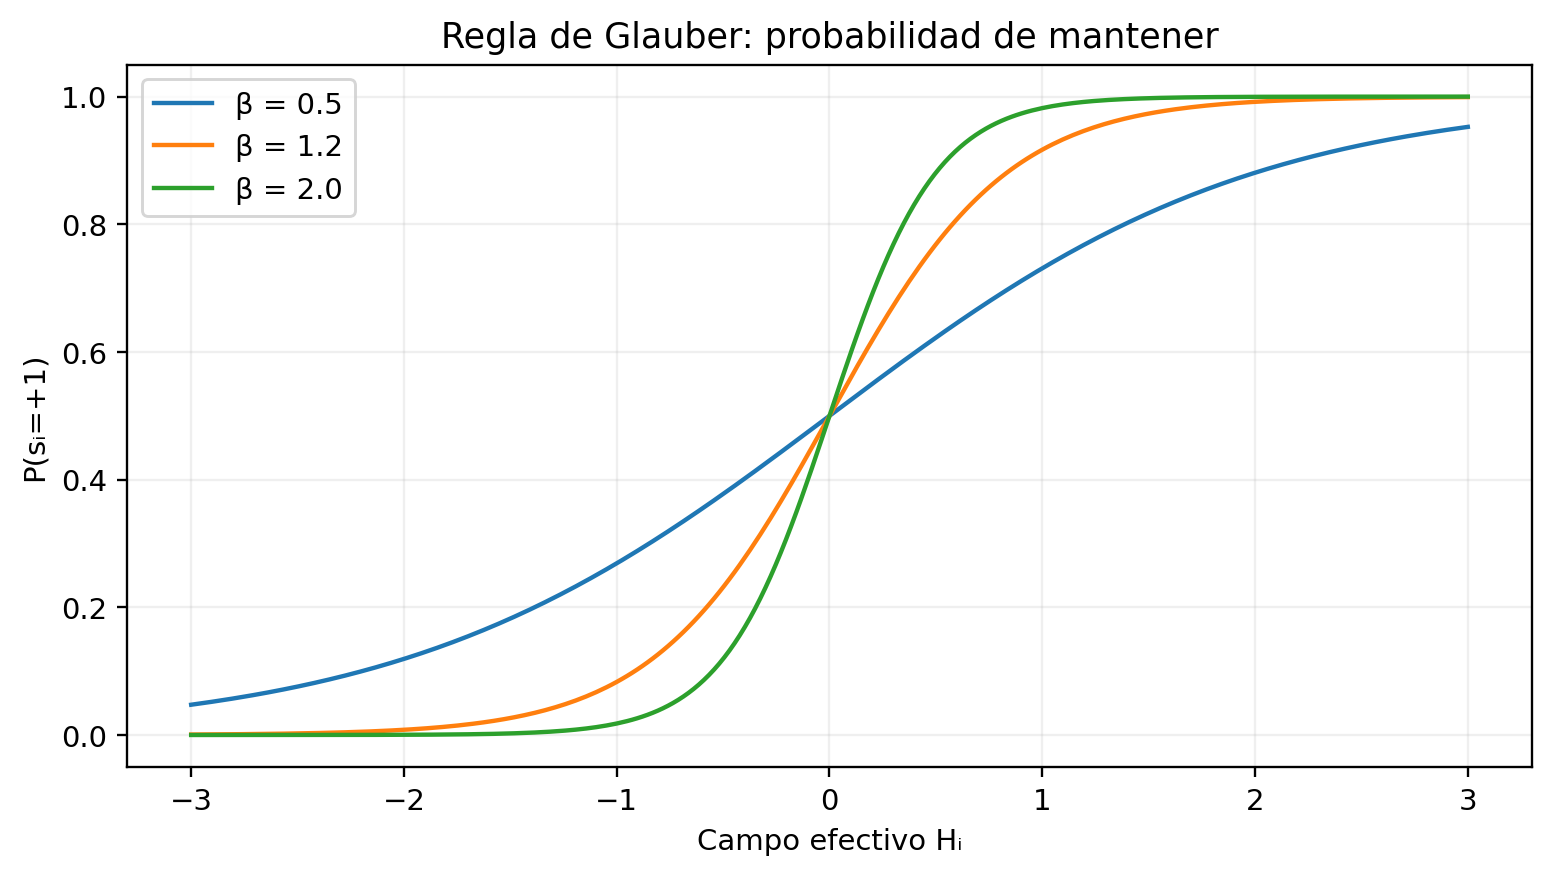

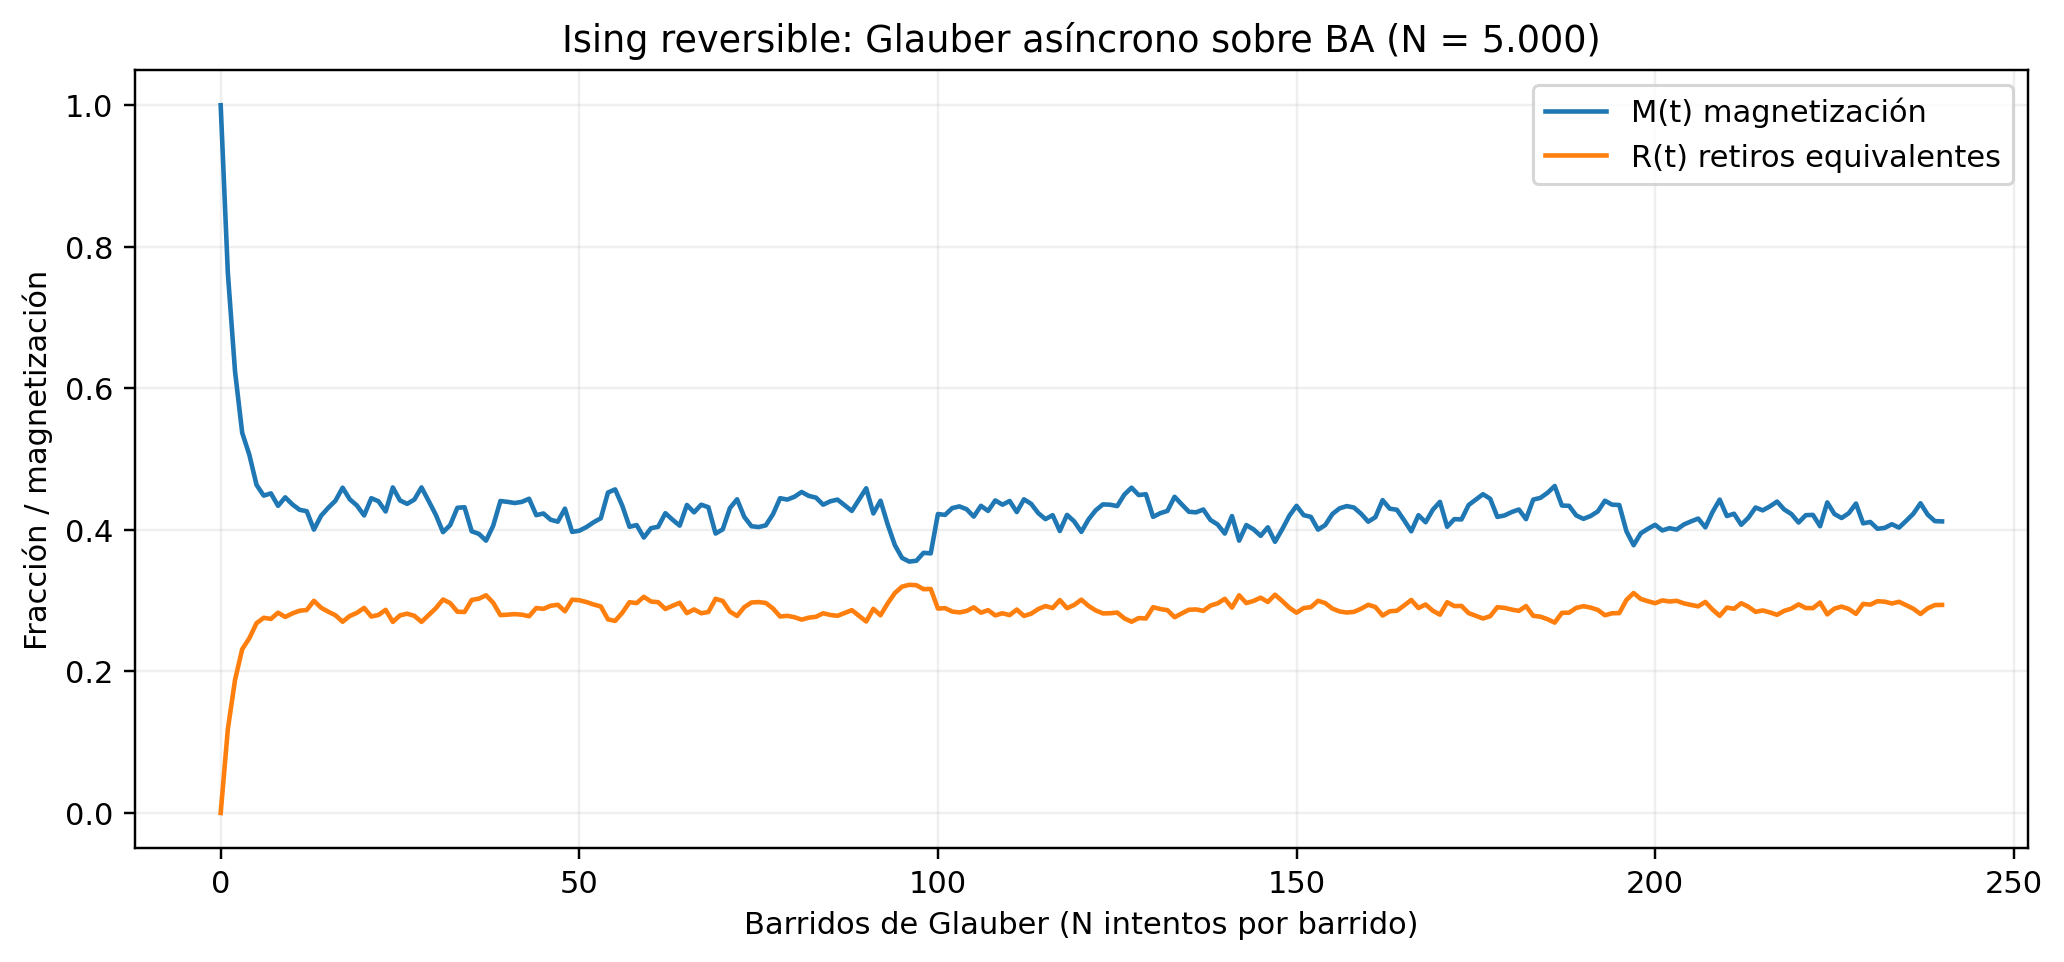

In [3]:
display(Image(filename=str(F/'10_glauber_logistica.png')))
display(Image(filename=str(F/'12_glauber_async_BA.png')))
assert np.allclose(pd.read_csv(D/'glauber_async_BA_N5000.csv')['R'],(1-pd.read_csv(D/'glauber_async_BA_N5000.csv')['M'])/2)

## 6. Diseño de la comparación de redes: dos mecanismos de shock

**Comparación controlada A (shock aleatorio):** se eligen $0.18N$ agentes de forma uniforme; se aplica $q=2.70$ durante nueve pasos. Se calcula $P(\mathrm{corrida})$, $\max_t R(t)$, el área $\int R(t)\,dt$, el tiempo de primer arribo y $L(T)$.

**Comparación controlada B (shock en hubs):** se afectan los $0.18N$ agentes con mayor grado de **cada red**. El resultado mide la combinación de topología y mecanismo de focalización; no aísla un efecto topológico universal.

**Control global:** el shock afecta a todos; se utilizan los parámetros separados $J=0.83$, $q=0.80$, $h_0=0.80$, $L_0=0.55$ para comprobar que una perturbación universal puede borrar parte del contraste entre redes.

Se estiman probabilidades con $B=18$ réplicas por red en el experimento de hubs y $B=12$ en los otros. Sus intervalos **exactos binomiales de Clopper–Pearson** cuantifican incertidumbre de Monte Carlo condicionada a una única red generada por topología. Para conclusiones poblacionales se necesitarían más realizaciones independientes de la red.

,red,tipo_shock,n_replicates,n_runs,p_run,ci_low,ci_high,peak_R_avg,final_L_avg,auc_R_avg
0,ER,hubs,18,0,0.0,0.0000,0.1853,0.4145,0.4715,5.2107
1,ER,random,12,0,0.0,0.0000,0.2646,0.3034,0.5028,4.0980
2,ER,global,12,12,1.0,0.7354,1.0000,0.7815,0.4446,6.3324
3,WS,hubs,18,0,0.0,0.0000,0.1853,0.3433,0.4918,4.4900
4,WS,random,12,0,0.0,0.0000,0.2646,0.3123,0.5008,4.1695
5,WS,global,12,12,1.0,0.7354,1.0000,0.7704,0.4459,6.2891
6,BA,hubs,18,18,1.0,0.8147,1.0000,0.7711,0.0000,18.0545
7,BA,random,12,0,0.0,0.0000,0.2646,0.3079,0.5009,4.1583
8,BA,global,12,12,1.0,0.7354,1.0000,0.7793,0.4438,6.3522


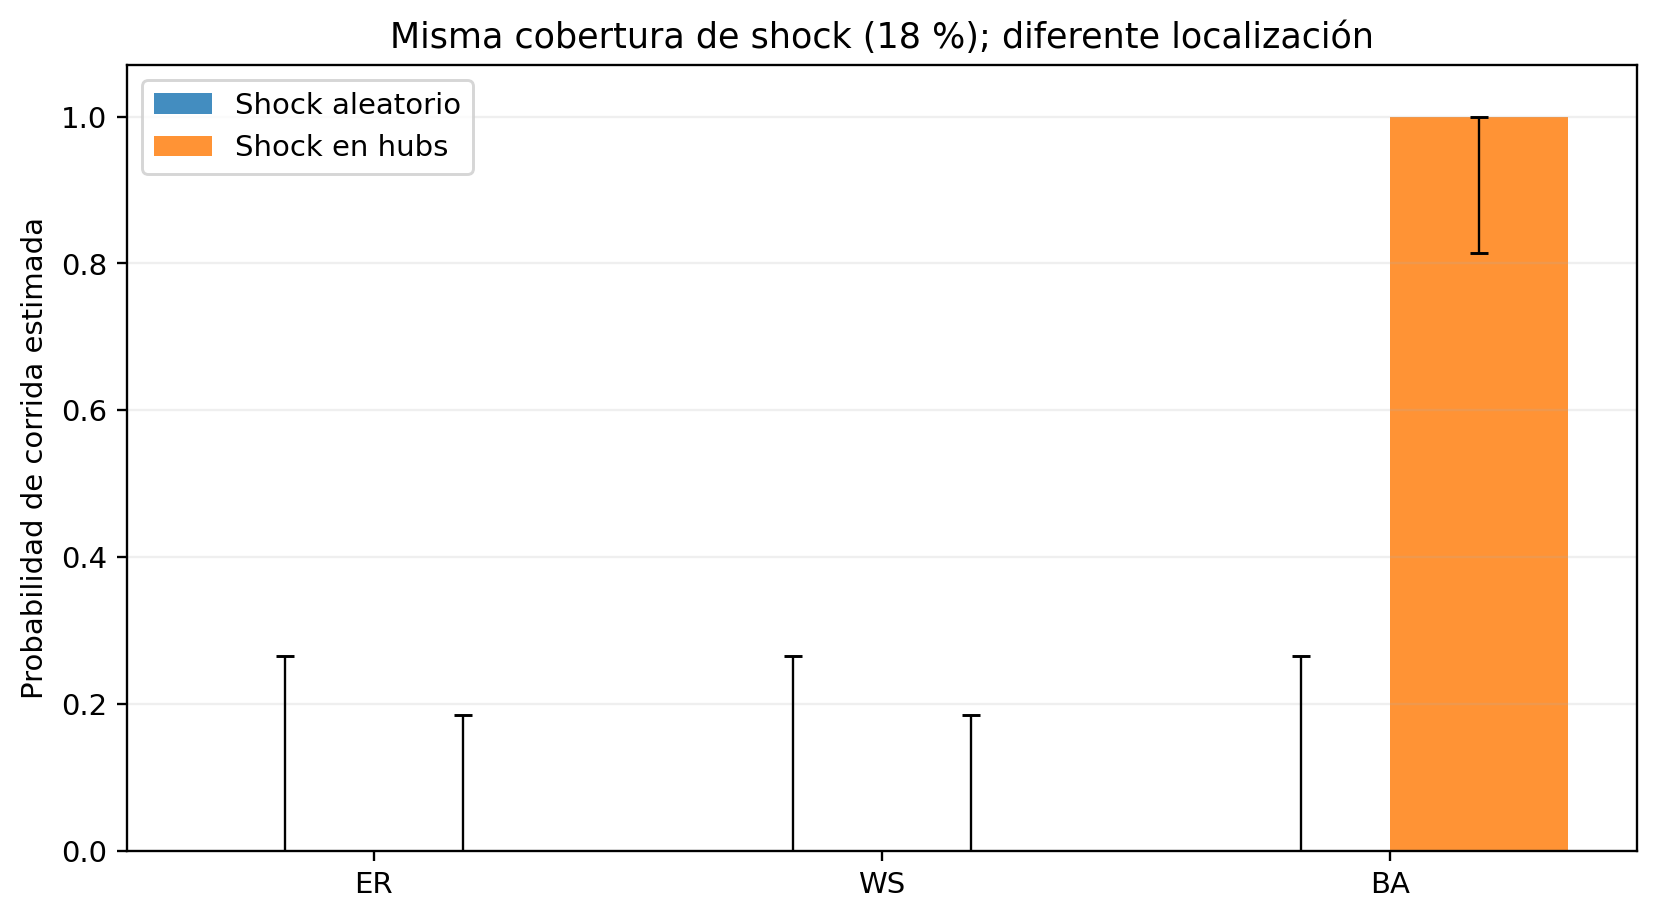

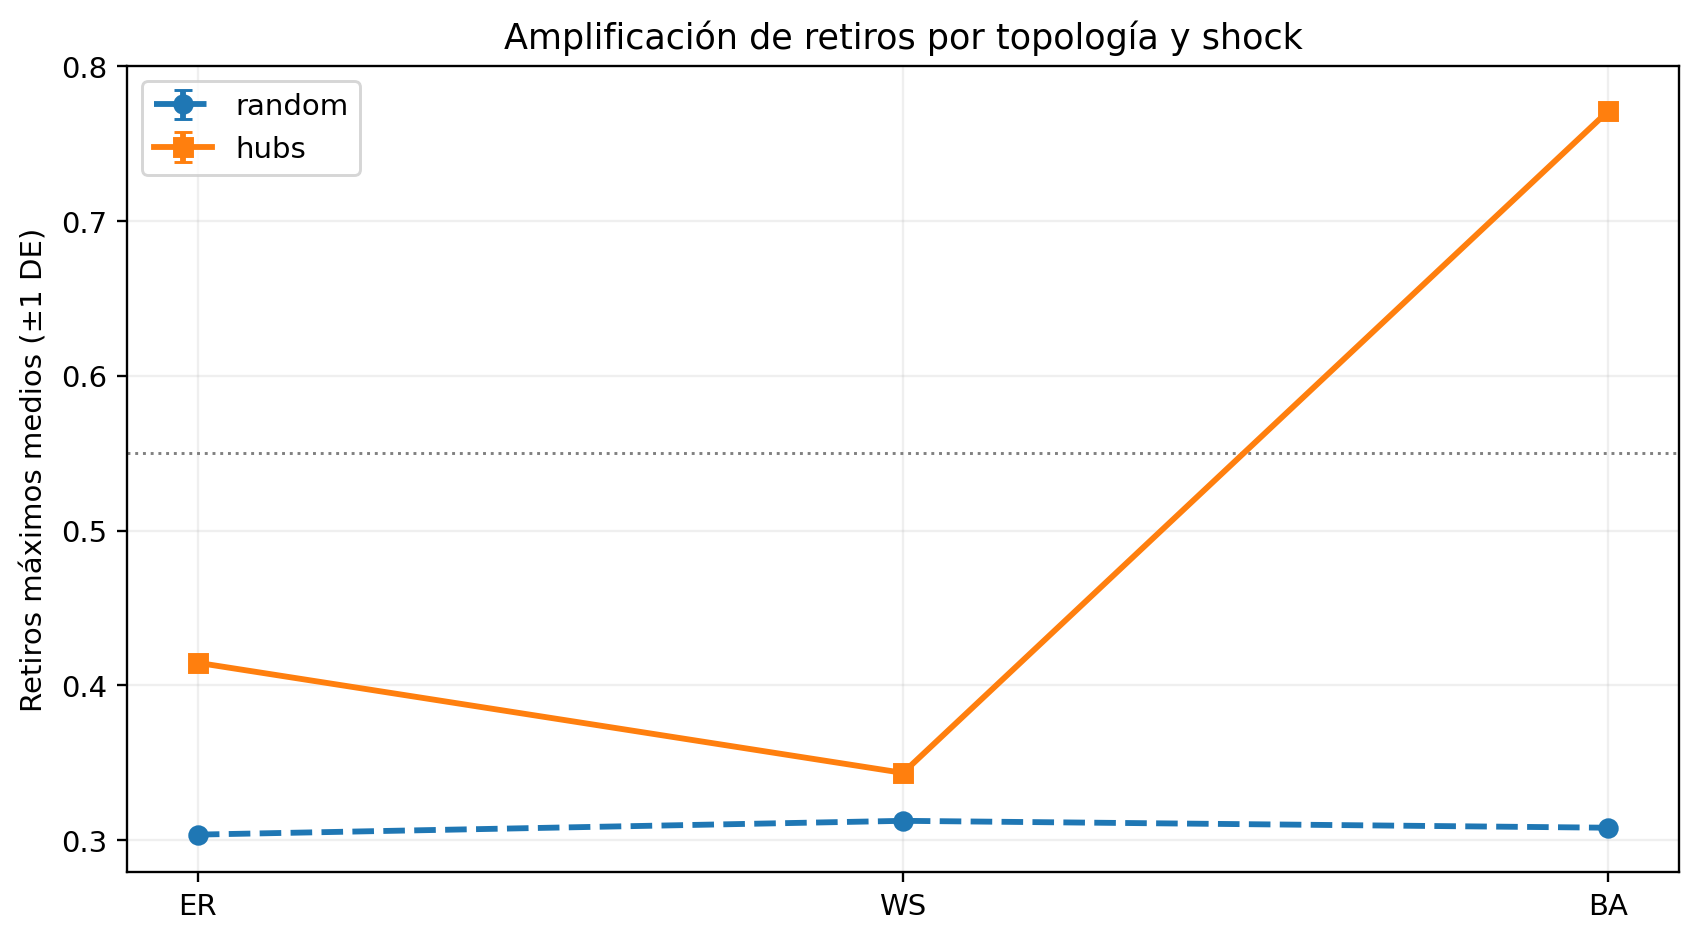

In [4]:
tab=pd.read_csv(D/'comparacion_topologias_N1M.csv')
cols=['red','tipo_shock','n_replicates','n_runs','p_run','ci_low','ci_high','peak_R_avg','final_L_avg','auc_R_avg']
display(tab[cols].round(4))
assert (tab.N==1_000_000).all()
assert (tab.p_run>=0).all() and (tab.p_run<=1).all()
display(Image(filename=str(F/'03_prob_corrido_localizacion_N1M.png')))
display(Image(filename=str(F/'04_picos_retiros_redes_N1M.png')))

## 7. Trayectorias de retiros y liquidez: 10 réplicas por topología

Las trayectorias permiten observar el *mecanismo*, no sólo el resultado final. El área sombreada marca el shock; las bandas de color son ± una desviación estándar de diez réplicas (no intervalos de confianza). El umbral operativo es $R=0.55$ durante tres pasos. La pérdida de liquidez puede persistir incluso cuando la fracción de retiros retrocede, porque $cR$ drena recursos en cada paso.

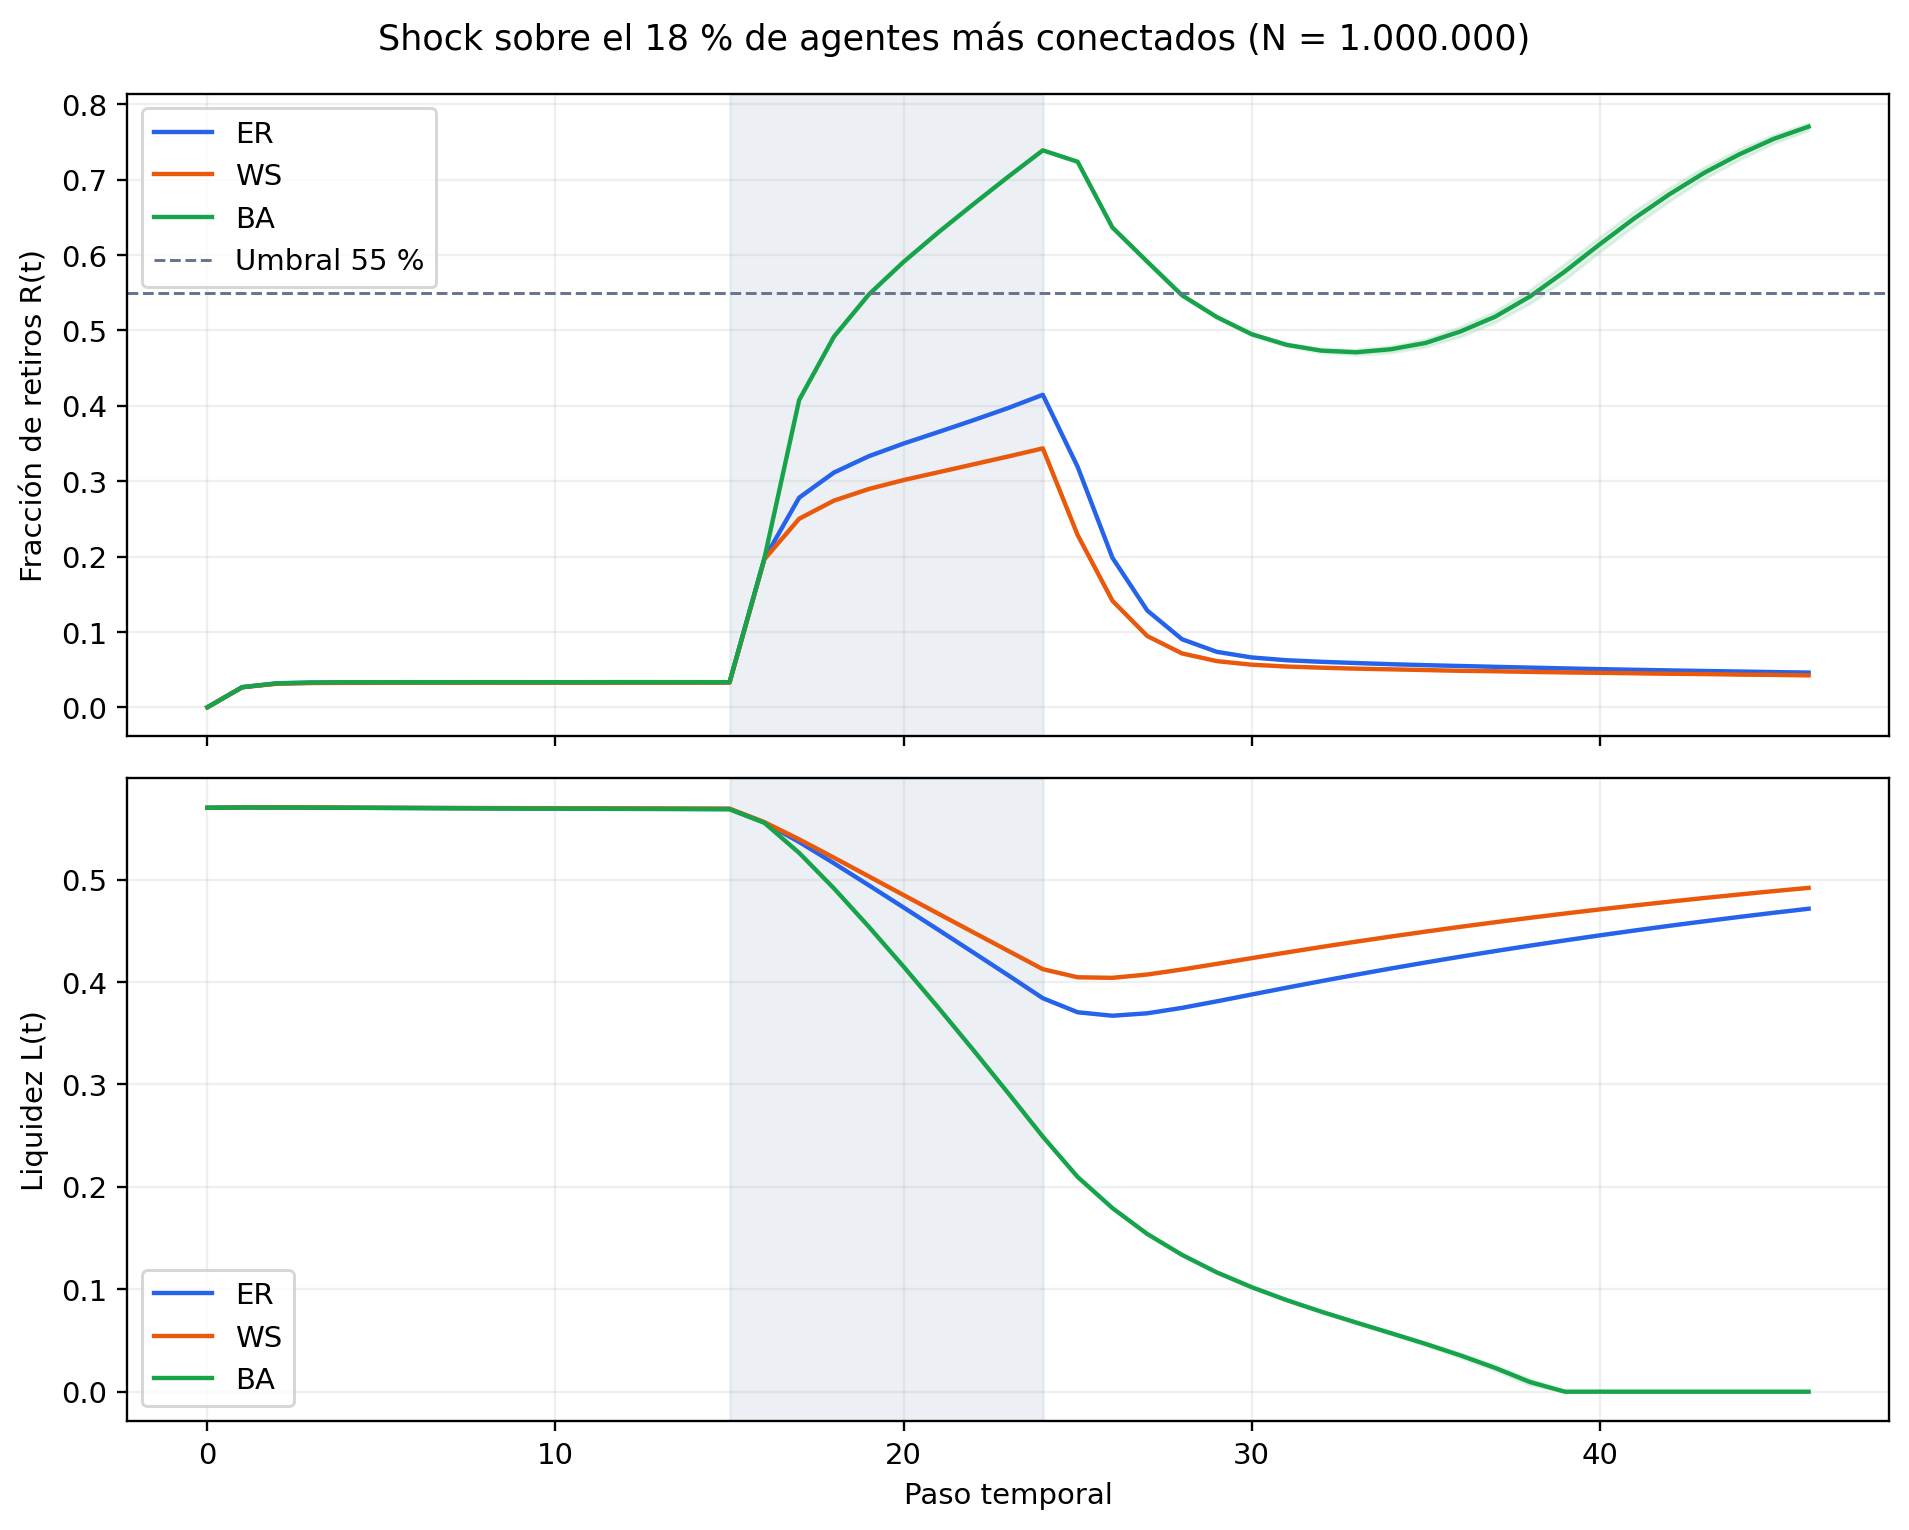

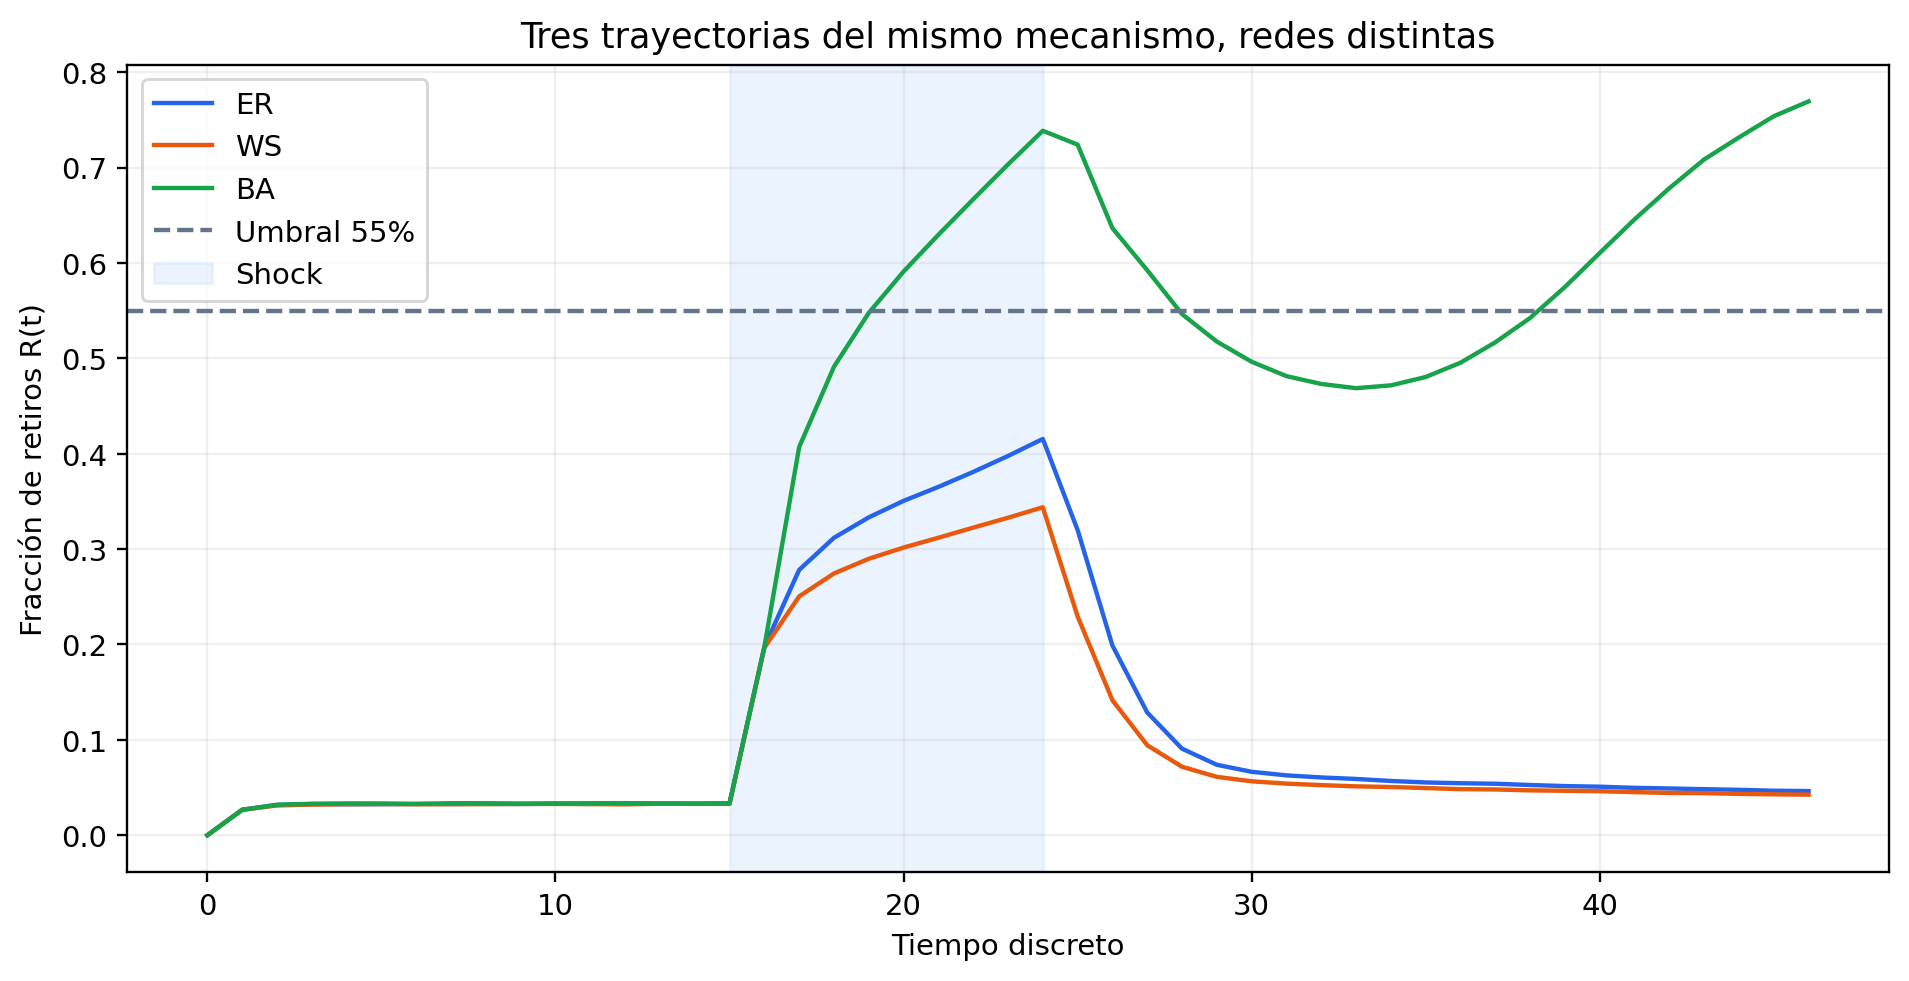

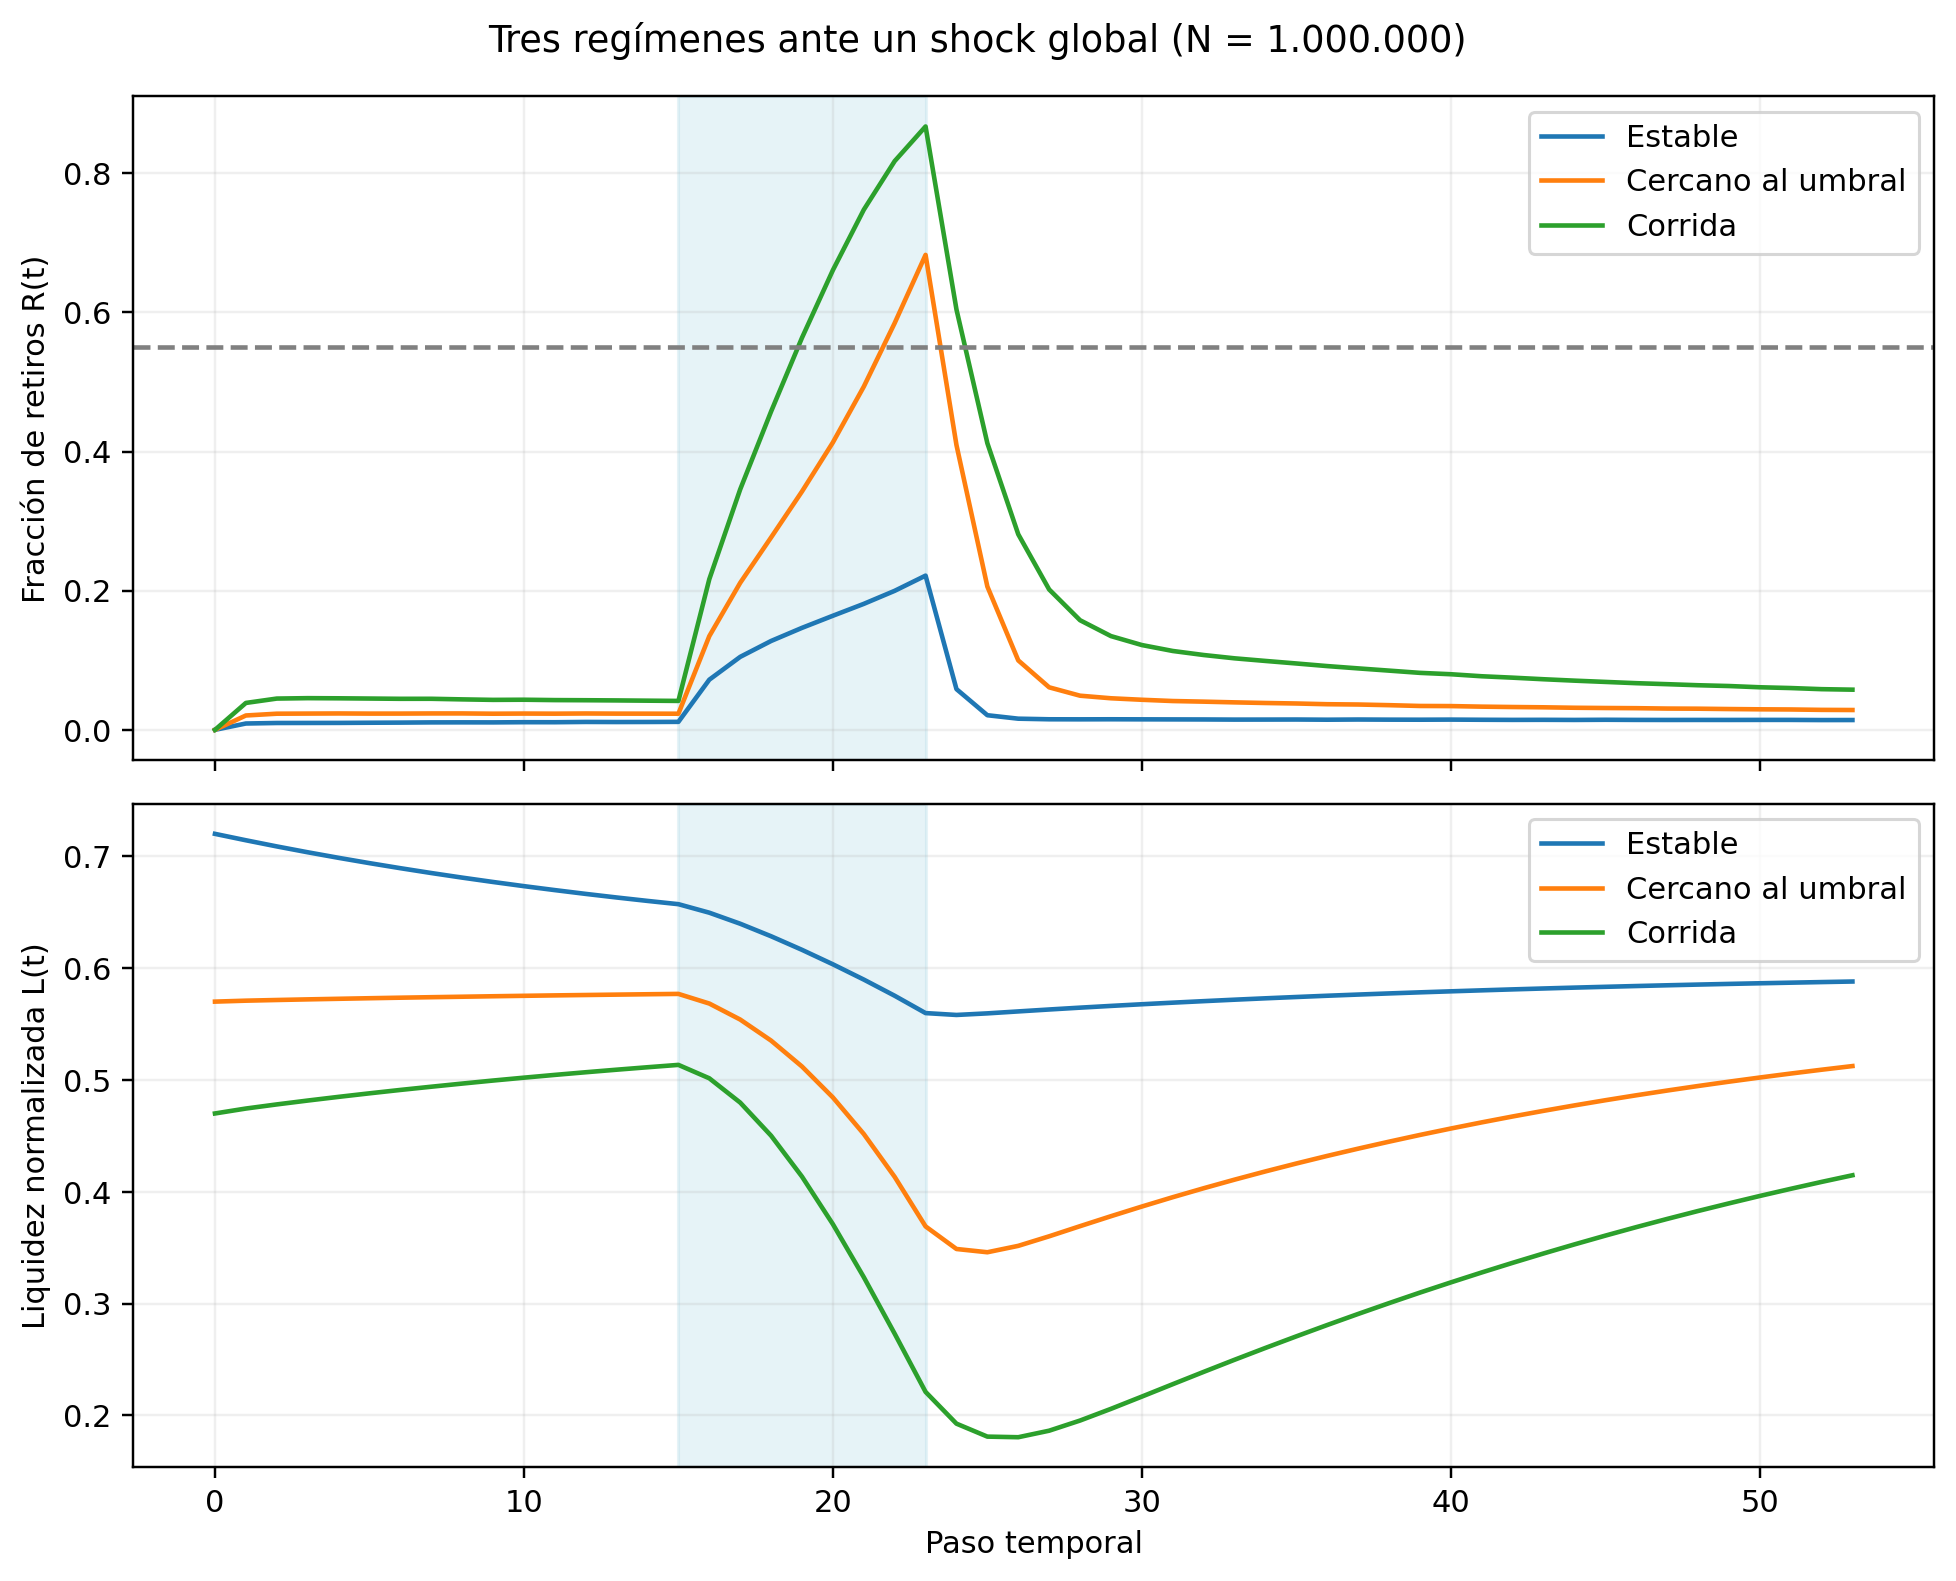

In [5]:
display(Image(filename=str(F/'02_dinamica_shock_hubs_N1M.png')))
display(Image(filename=str(F/'06_trayectorias_ER_WS_BA_N1M.png')))
display(Image(filename=str(F/'13_trayectorias_estable_umbral_corrida.png')))

## 8. Sensibilidad paramétrica: liquidez inicial, shock y contacto social

En ER con $N=1\,000\,000$ se evalúa una **malla exploratoria** de $J\times L_0$ bajo shock global y otra de $q\times L_0$. Se realizan solamente **tres réplicas por celda** para localizar regiones sensibles. Una celda con 0 o 3 corridas **no** implica probabilidad real 0 o 1; el paso de la escala es $1/3$. Para informar una probabilidad estable, se debe refinar el barrido cerca de la frontera usando por ejemplo $B\ge100$ y varias redes independientes.

**Preguntas:** ¿Cuánto aumenta la probabilidad de corrida cuando disminuye $L_0$? ¿La intensidad $q$ tiene un efecto gradual o presenta una frontera no lineal? ¿El aumento de $J$ protege un consenso inicialmente positivo?

,J,L0,p_run,ci_low,ci_high,peak_R_avg,B,N
0,0.72,0.42,1.0,0.4644,0.9998,0.8895,3,1000000
1,0.82,0.42,1.0,0.4644,0.9998,0.8856,3,1000000
2,0.92,0.42,1.0,0.4644,0.9998,0.8570,3,1000000
3,1.02,0.42,1.0,0.4644,0.9998,0.7670,3,1000000
4,1.12,0.42,0.0,0.0002,0.5356,0.5791,3,1000000


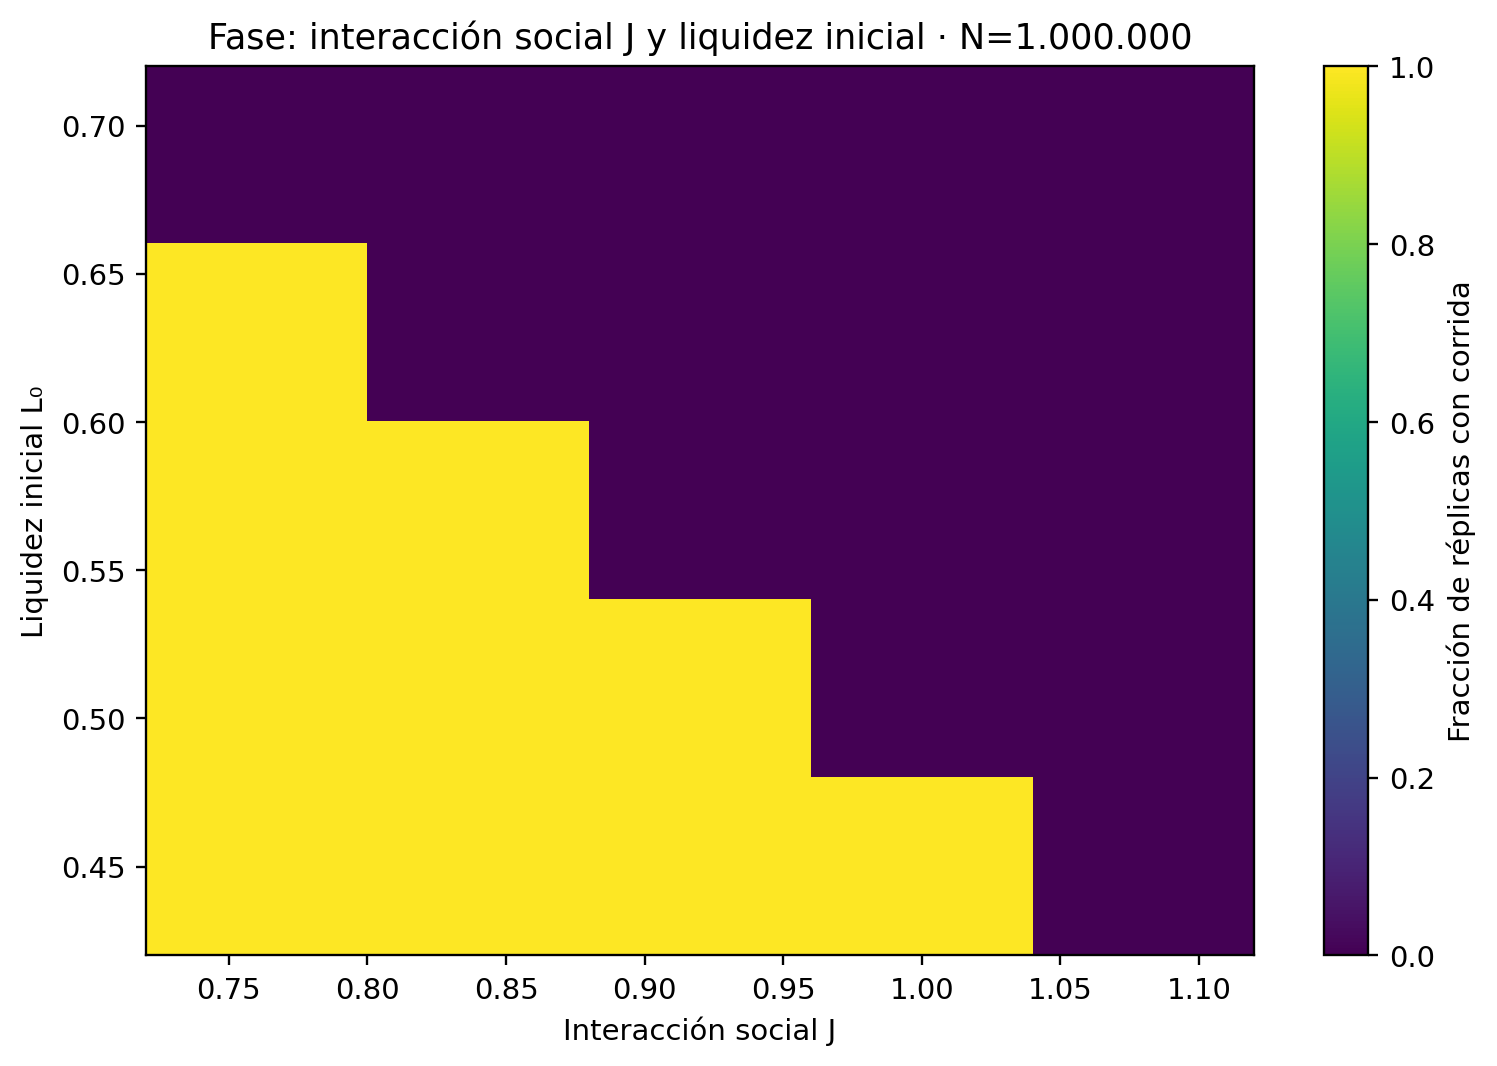

,L0,q,p_run,ci_low,ci_high,peak_R_avg,B,N
0,0.42,0.50,0.0,0.0002,0.5356,0.1916,3,1000000
1,0.42,0.63,0.0,0.0002,0.5356,0.4279,3,1000000
2,0.42,0.76,1.0,0.4644,0.9998,0.8080,3,1000000
3,0.42,0.89,1.0,0.4644,0.9998,0.9429,3,1000000
4,0.42,1.02,1.0,0.4644,0.9998,0.9701,3,1000000


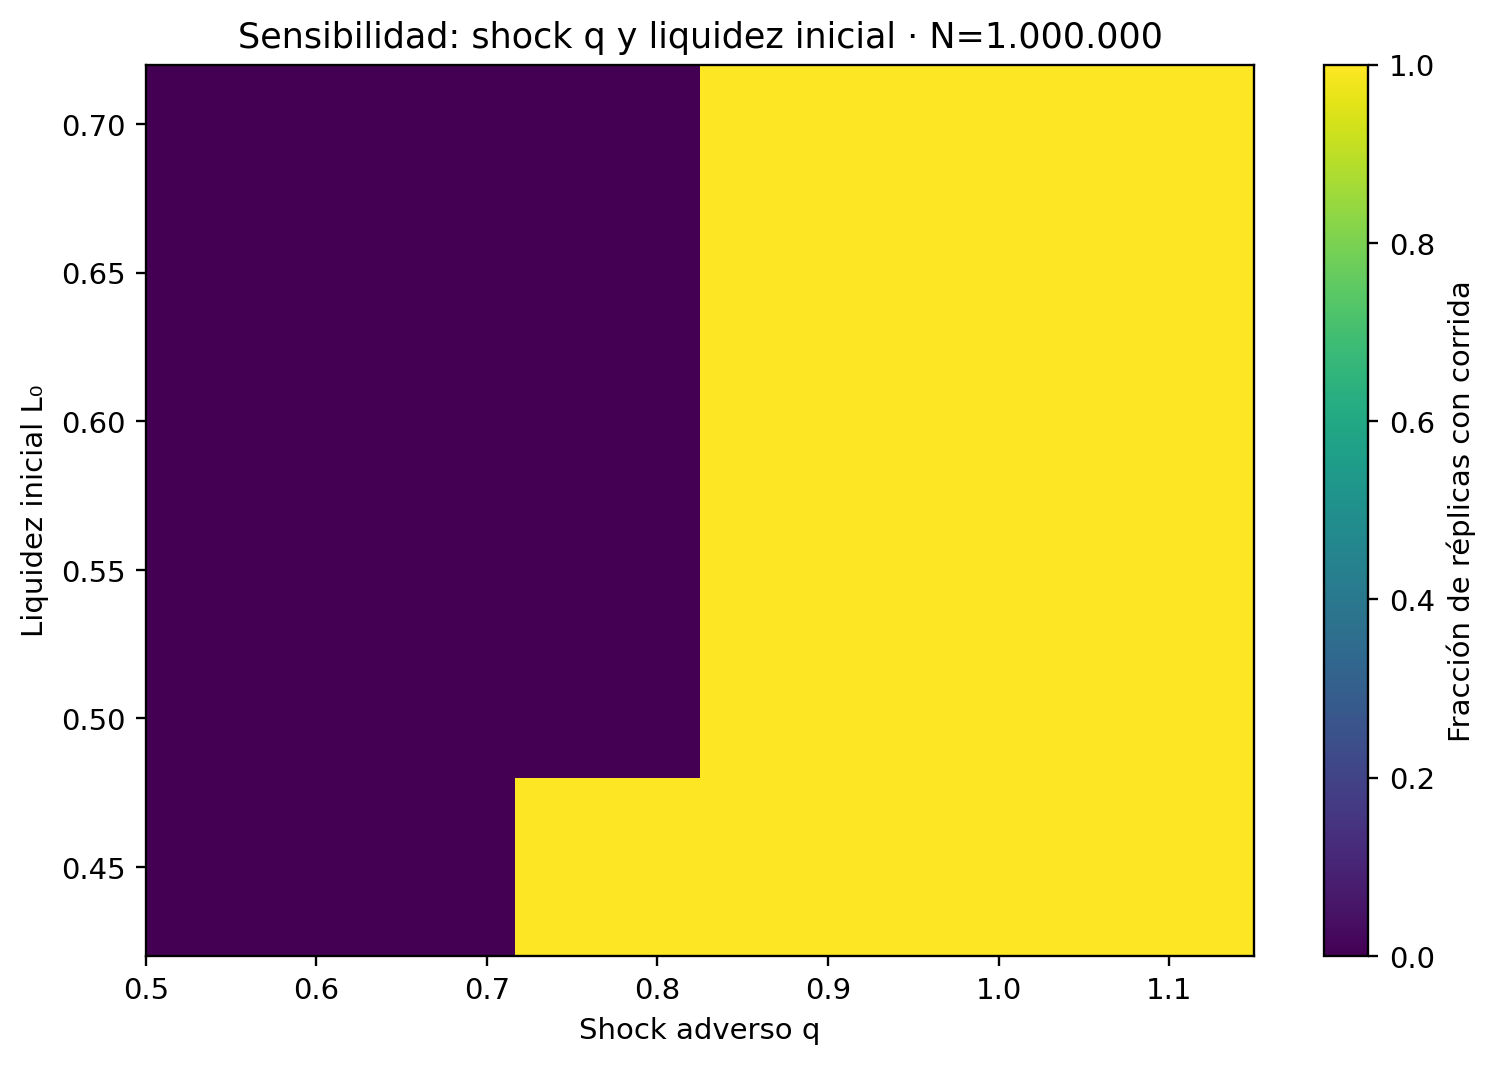

In [6]:
display(pd.read_csv(D/'fase_J_L0_N1M.csv').head().round(4))
display(Image(filename=str(F/'07_fase_J_L0_N1M.png')))
display(pd.read_csv(D/'sensibilidad_L0_q_N1M.csv').head().round(4))
display(Image(filename=str(F/'08_sensibilidad_L0_q_N1M.png')))

## 9. Curvas de orden y sensibilidad $\beta$ en Ising sin liquidez

Para separar magnetización y corrida se estudia el submodelo $h=0$, sin liquidez, con actualización de baño térmico sincrónica. Se grafica $\langle|M|\rangle$ frente a $\beta=1/T$. $\beta$ elevada refuerza el orden. Estas curvas **no** se deben interpretar directamente como probabilidades de corrida; constituyen un experimento auxiliar de física estadística.

Con $W$ normalizada por filas, $\rho(W)\approx1$ en redes sin aislados, por lo que el criterio lineal $\beta J\rho(W)\approx1$ tiene limitaciones para distinguir las topologías. La heterogeneidad y la localización del shock aportan información adicional.

,red,beta,abs_M,sd,B,N
0,ER,0.5500,0.0009,0.0001,2,1000000
1,ER,0.6875,0.0008,0.0001,2,1000000
2,ER,0.8250,0.0011,0.0005,2,1000000
3,ER,0.9625,0.0018,0.0002,2,1000000
4,ER,1.1000,0.0837,0.0030,2,1000000
5,ER,1.2375,0.5019,0.0006,2,1000000
6,ER,1.3750,0.7087,0.0001,2,1000000
7,ER,1.5125,0.8125,0.0003,2,1000000
8,ER,1.6500,0.8738,0.0000,2,1000000


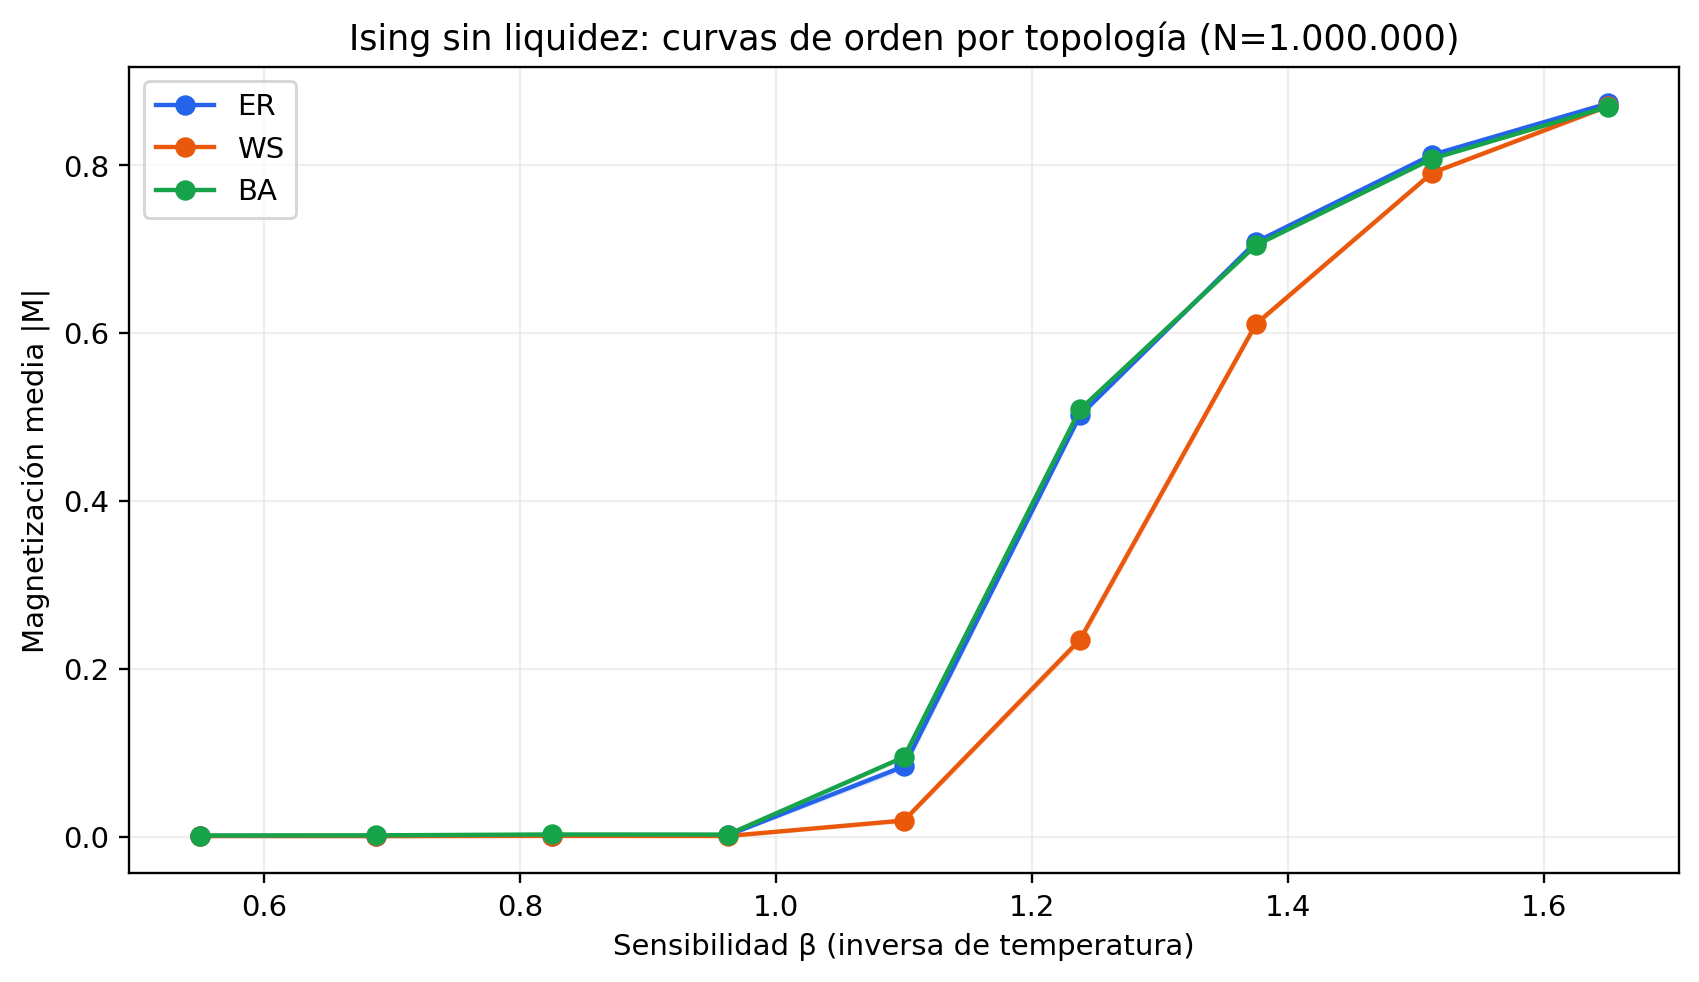

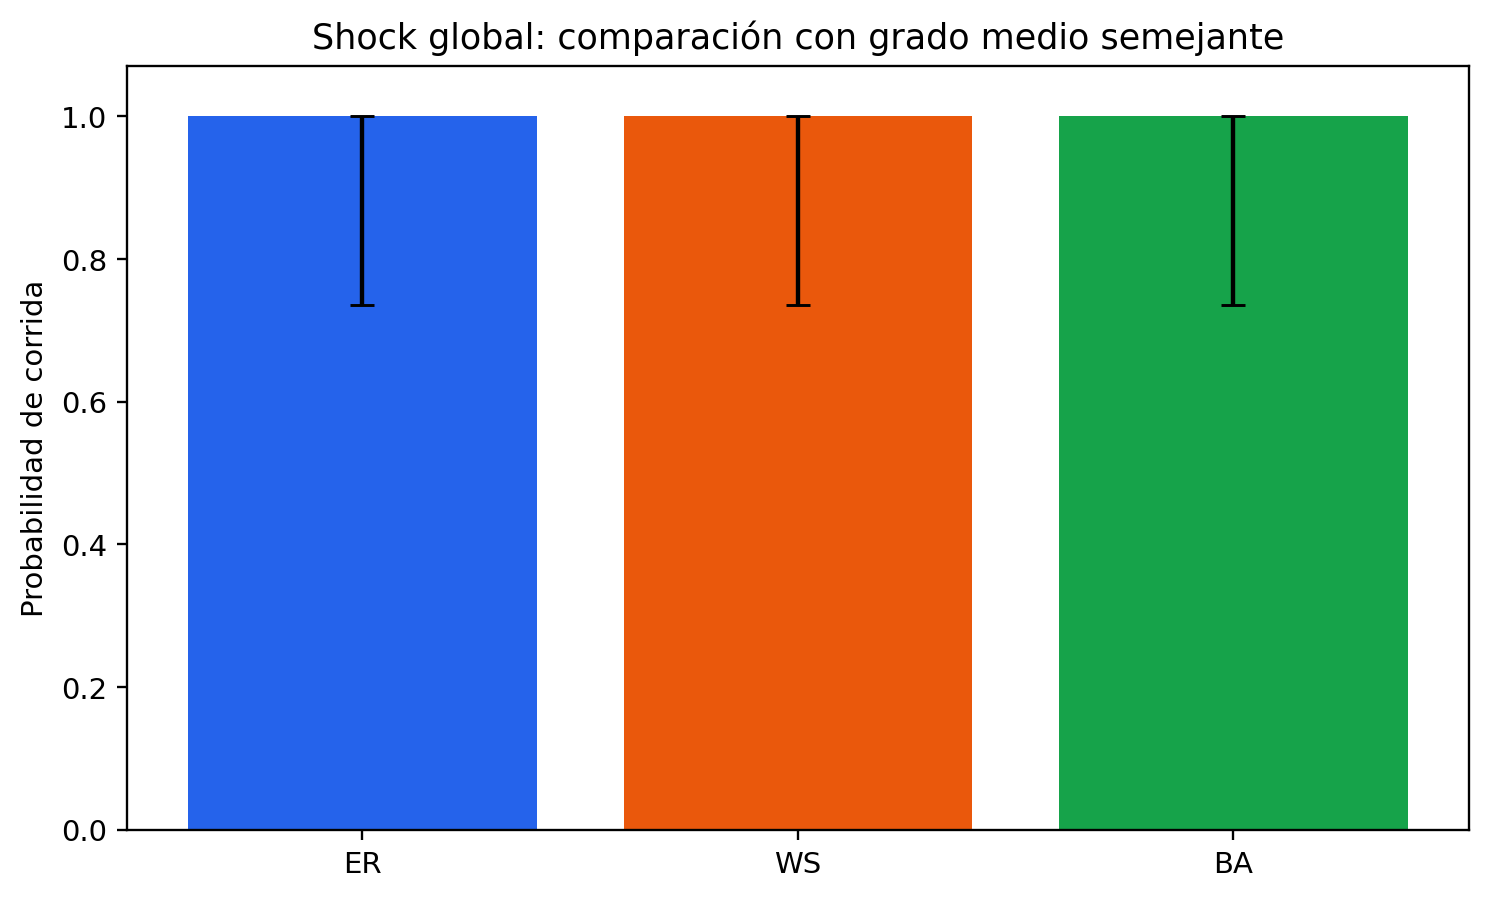

In [7]:
display(pd.read_csv(D/'curvas_orden_beta_N1M.csv').head(9).round(4))
display(Image(filename=str(F/'09_curvas_orden_beta_N1M.png')))
display(Image(filename=str(F/'05_shock_global_comparacion_N1M.png')))

## 10. Marco interpretativo: juegos globales y fragilidad bancaria

**Morris y Shin (1998)** muestran cómo señales privadas imperfectas pueden seleccionar un equilibrio en un juego de ataques especulativos. **Goldstein y Pauzner (2005)** aplican un enfoque de juegos globales a contratos de depósito y a la probabilidad de corridas bancarias. El presente estudio **no implementa su solución estratégica de equilibrio**, sino que utiliza una dinámica probabilística de agentes para representar imitación y retroalimentación de liquidez. La comparación permite formular una hipótesis metodológica: introducir señales privadas y heterogeneidad de información podría ayudar a conectar ambas familias de modelos.

Referencias verificadas:

- Morris, S., & Shin, H. S. (1998). Unique equilibrium in a model of self-fulfilling currency attacks. *American Economic Review, 88*(3), 587–597.
- Goldstein, I., & Pauzner, A. (2005). Demand–deposit contracts and the probability of bank runs. *The Journal of Finance, 60*(3), 1293–1327. https://doi.org/10.1111/j.1540-6261.2005.00762.x

## 11. Reproducibilidad completa: cómo recalcular $N=1\,000\,000$

El cuaderno muestra resultados ejecutados, pero también puede regenerarlos. Las simulaciones usan `NumPy`, `SciPy`, `Numba`, `NetworkX`, `Matplotlib` y `pandas`. Los generadores tienen semillas fijas. Ejecutar todas las fases puede tardar varios minutos y depende de RAM/CPU; se recomienda al menos 8 GB de memoria. El `README.md` explica cada archivo.

`ising_1m_core.py`: definición del modelo, generadores dispersos de redes y criterio operativo.

`run_study.py`: comparación por topología, barridos $(J,L_0)$ y $(q,L_0)$, y curvas de orden.

`extra_figures.py`: gráficos de tres regímenes, topologías esquemáticas y Glauber asincrónico independiente.

El parámetro `RECALCULAR=False` evita recomputar de manera accidental cientos de millones de decisiones.

In [8]:
RECALCULAR=False
if RECALCULAR:
    import subprocess
    def run(*args):
        subprocess.run([sys.executable,str(ROOT/'code'/'run_study.py'),*args],cwd=ROOT,check=True)
    for red in ['ER','WS','BA']:
        for modo in ['hubs','random','global']:
            run('one',red,modo)
    run('assemble')
    for cual in ['fase','sens']:
        for fila in range(5):run('row',cual,str(fila))
    run('assemblegrids')
    for red in ['ER','WS','BA']:run('oneorder',red)
    run('assembleorder')
    run('figures')
    subprocess.run([sys.executable,str(ROOT/'code'/'extra_figures.py')],cwd=ROOT,check=True)
else:
    print('Se leen los resultados previamente calculados; cambie RECALCULAR=True para replicar la investigación.')

Se leen los resultados previamente calculados; cambie RECALCULAR=True para replicar la investigación.


## 12. Pruebas de coherencia y auditoría numérica

- El estado binario impone $R(t)=(1-M(t))/2$.
- El algoritmo exige **tres puntos consecutivos** por encima de $r_c$, y no un máximo aislado.
- Se comparan redes con el mismo grado medio aproximado y $N$ igual; WS presenta menor heterogeneidad de grado, BA mayor.
- Los intervalos exactos de binomiales reflejan incertidumbre por réplicas, pero **no** capturan incertidumbre de estructura de red si el grafo se mantiene fijo.
- Aumentar $N$ no sustituye aumentar $B$, ni calibrar parámetros con observaciones.
- Los resultados de shock localizado se condicionan a la regla de selección de destinatarios; no son una ley sobre todos los shocks.
- Las gráficas de Glauber asíncrono y de Ising sin liquidez son auxiliares: no se emplean para afirmar que el modelo bancario no estacionario tenga medida de Gibbs.


In [9]:
df=pd.read_csv(D/'trayectorias_10porred_N1M.csv')
assert np.allclose(df['R'].values,(1-df['M'].values)/2,rtol=1e-5,atol=2e-6)
metrics=pd.read_csv(D/'metricas_redes_N1M.csv')
assert np.all(np.abs(metrics['mean_degree']-8)<0.03)
assert metrics.loc[metrics.red=='BA','cv_degree'].iloc[0]>metrics.loc[metrics.red=='ER','cv_degree'].iloc[0]
assert metrics.loc[metrics.red=='ER','cv_degree'].iloc[0]>metrics.loc[metrics.red=='WS','cv_degree'].iloc[0]
print('Coherencia macro, escala N y heterogeneidad estructural: OK')

Coherencia macro, escala N y heterogeneidad estructural: OK


## 13. Síntesis e interpretación científica

**Hallazgo numérico condicionado:** bajo el shock concentrado en el 18 % de nodos de mayor grado ($q=2.70$, $J=1.00$, $h_0=0.60$, $L_0=0.57$), BA presentó corridas en todas las 18 réplicas y ER/WS en ninguna. La misma fracción afectada pero **aleatoria** no produjo corridas en las 12 réplicas de cada red. Bajo shock **global** (otros parámetros, documentados), las tres redes presentaron corridas.

La interpretación correcta es que **topología y localización del shock interactúan**. La heterogeneidad de los grados modifica quiénes reciben primero la noticia y cómo se propaga la desconfianza; el efecto no puede atribuirse exclusivamente al modelo de red sin controlar el mecanismo de perturbación.

**Limitaciones:** parámetros adimensionales no calibrados; una red por topología; criterio operativo arbitrario del 55 % y tres pasos; igual volumen por agente; no se modelan múltiples bancos, balances reales ni retiros parciales. Los barridos con $B=3$ son mapas exploratorios, no estimaciones precisas. La investigación valida internamente un **modelo sintético** y formula hipótesis cuantitativas susceptibles de validación posterior.

In [10]:
for k in ['comparacion_topologias_N1M.csv','metricas_redes_N1M.csv','fase_J_L0_N1M.csv','sensibilidad_L0_q_N1M.csv','curvas_orden_beta_N1M.csv']:
    print(k, (D/k).stat().st_size, 'bytes')
print('Figuras',len(list(F.glob('*.png'))))

comparacion_topologias_N1M.csv 1463 bytes
metricas_redes_N1M.csv 305 bytes
fase_J_L0_N1M.csv 2144 bytes
sensibilidad_L0_q_N1M.csv 2546 bytes
curvas_orden_beta_N1M.csv 1602 bytes
Figuras 13
